In [100]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [101]:
df = pd.read_csv('dataset/weatherHistory.csv')
# df = df.drop(columns=['Summary'])
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 96453 entries, 0 to 96452
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Formatted Date            96453 non-null  object 
 1   Summary                   96453 non-null  object 
 2   Precip Type               95936 non-null  object 
 3   Temperature (C)           96453 non-null  float64
 4   Apparent Temperature (C)  96453 non-null  float64
 5   Humidity                  96453 non-null  float64
 6   Wind Speed (km/h)         96453 non-null  float64
 7   Wind Bearing (degrees)    96453 non-null  float64
 8   Visibility (km)           96453 non-null  float64
 9   Loud Cover                96453 non-null  float64
 10  Pressure (millibars)      96453 non-null  float64
 11  Daily Summary             96453 non-null  object 
dtypes: float64(8), object(4)
memory usage: 8.8+ MB


In [102]:
df = df.drop(['Formatted Date', 'Summary', 'Precip Type', 'Daily Summary', 'Loud Cover'], axis=1)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 96453 entries, 0 to 96452
Data columns (total 7 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Temperature (C)           96453 non-null  float64
 1   Apparent Temperature (C)  96453 non-null  float64
 2   Humidity                  96453 non-null  float64
 3   Wind Speed (km/h)         96453 non-null  float64
 4   Wind Bearing (degrees)    96453 non-null  float64
 5   Visibility (km)           96453 non-null  float64
 6   Pressure (millibars)      96453 non-null  float64
dtypes: float64(7)
memory usage: 5.2 MB


In [103]:
X = df.drop(['Humidity'], axis=1)
y = df['Humidity']

In [104]:
# train : val : test = 70 : 15 : 15

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=100)

X_test, X_val, y_test, y_val = train_test_split(X_temp, y_temp, test_size=0.5, random_state=100)

print(X_train.shape, X_test.shape, X_val.shape)

(67517, 6) (14468, 6) (14468, 6)


In [105]:
# standardize -> z = (x - mean) / std

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train, y_train)
X_test = scaler.transform(X_test)
X_val = scaler.transform(X_val)

In [106]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(8, activation='relu'),
    tf.keras.layers.Dense(1, activation='linear')
])

In [107]:
model.compile(optimizer='adam', loss='mse', metrics=['mae'])

model.summary()

Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_8 (Dense)             (None, 32)                224       
                                                                 
 dense_9 (Dense)             (None, 16)                528       
                                                                 
 dense_10 (Dense)            (None, 8)                 136       
                                                                 
 dense_11 (Dense)            (None, 1)                 9         
                                                                 
Total params: 897
Trainable params: 897
Non-trainable params: 0
_________________________________________________________________


In [108]:
history = model.fit(
    X_train, y_train, 
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=256
)

Epoch 1/50
264/264 [==============================] - 3s 8ms/step - loss: 0.3957 - mae: 0.5628 - val_loss: 0.0390 - val_mae: 0.1620
Epoch 2/50
264/264 [==============================] - 2s 7ms/step - loss: 0.0271 - mae: 0.1324 - val_loss: 0.0221 - val_mae: 0.1189
Epoch 3/50
264/264 [==============================] - 2s 7ms/step - loss: 0.0192 - mae: 0.1090 - val_loss: 0.0174 - val_mae: 0.1031
Epoch 4/50
264/264 [==============================] - 2s 8ms/step - loss: 0.0167 - mae: 0.0995 - val_loss: 0.0161 - val_mae: 0.0980
Epoch 5/50
264/264 [==============================] - 2s 8ms/step - loss: 0.0158 - mae: 0.0959 - val_loss: 0.0154 - val_mae: 0.0947
Epoch 6/50
264/264 [==============================] - 2s 7ms/step - loss: 0.0153 - mae: 0.0940 - val_loss: 0.0150 - val_mae: 0.0934
Epoch 7/50
264/264 [==============================] - 2s 6ms/step - loss: 0.0149 - mae: 0.0925 - val_loss: 0.0145 - val_mae: 0.0912
Epoch 8/50
264/264 [==============================] - 2s 6ms/step - loss: 0.

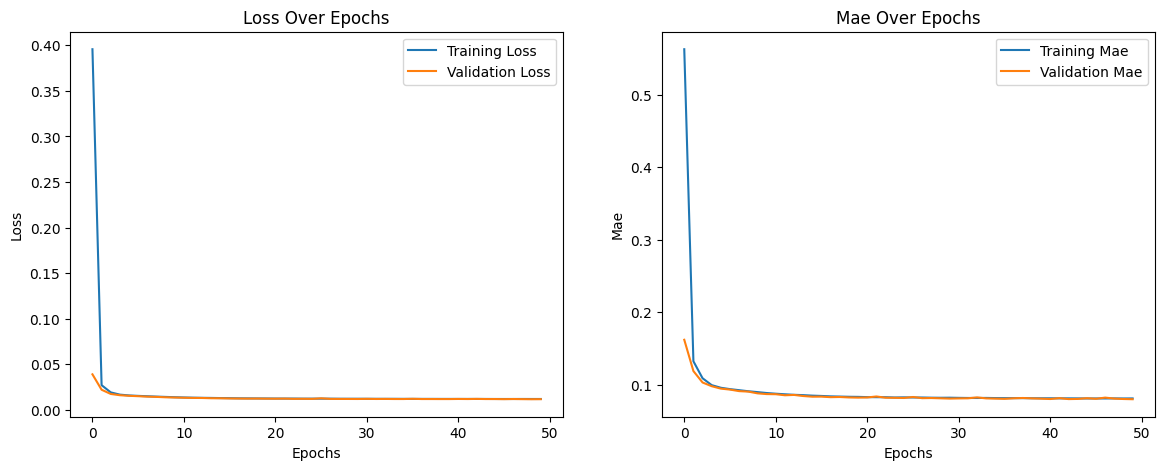

In [109]:
plt.figure(figsize=(14,5))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss Over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['mae'], label='Training Mae')
plt.plot(history.history['val_mae'], label='Validation Mae')
plt.title('Mae Over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Mae')
plt.legend()

In [110]:
test_mse, test_mae = model.evaluate(X_test, y_test)
print(f'Test MSE: {test_mse:.5f}')
print(f'Test MAE: {test_mae:.5f}')

453/453 [==============================] - 2s 4ms/step - loss: 0.0125 - mae: 0.0826
Test MSE: 0.01248
Test MAE: 0.08262


In [111]:
baseline_mse = float(((y_test - y_train.mean()) ** 2).mean())

print(f'R2: {1 - test_mse / baseline_mse:.3f}')

R2: 0.675


In [112]:
sample = [9.472222222222221,7.3888888888888875,14.1197,251.0,15.826300000000002,1015.13]

sample_df = pd.DataFrame([sample], columns=X.columns)
sample_scale = scaler.transform(sample_df)
prediction = model.predict(sample_scale)

print(f'Prediction Humidity: {prediction[0][0]:.5f}')

1/1 [==============================] - 0s 52ms/step
Prediction Humidity: 0.74704
